# 03 — Clustering the SA2s

**Mini Project 2.** K-Means on the scaled socio-economic profile of each SA2,
interpretation of the resulting groups, and the check on whether those groups
have anything to do with the administrative geographies the client plans against.

Two questions:

1. What natural groupings of New Zealand areas exist in the census profile?
2. How far do those groupings agree with regional council and territorial
   authority?

The feature list is **not** decided here. It is read from
`outputs/feature_spec.json`, written by notebook 02, so that 03 and 04 cluster
and model on exactly the same columns.

### What the feature list contains
50 numeric features: the income, rent, tenure, landlord, motor-vehicle and
telecommunications bracket **shares**, plus `suppressed_n`. No categoricals —
the administrative and urban/rural columns are not in the frame, so the
clustering works on the socio-economic profile alone.

Household composition and usual-resident counts are deliberately excluded:
crowding is defined as composition against a bedroom requirement, so those
columns are the outcome in another form. Their effect is tested separately at
the end.


In [1]:
import sys, json
from pathlib import Path
if "../src" not in sys.path:
    sys.path.append("../src")
import mp2

spec_path = mp2.OUT / "feature_spec.json"
spec = json.loads(spec_path.read_text())

numeric_cols = spec.get("numeric", [])
categorical_cols = spec.get("categorical", [])
cluster_cols = [c for c in numeric_cols if c != "suppressed_n"]

print("=== outputs/feature_spec.json Summary ===")
print("Keys         :", list(spec.keys()))
print("Target       :", spec.get("target"))
print("n_rows       :", spec.get("n_rows"))
print(f"Numeric cols : {len(numeric_cols)} (clustering matrix without suppressed_n: {len(cluster_cols)})")
print(f"Categorical  : {len(categorical_cols)} -> {categorical_cols}")
print(f"Leaky / ID   : {len(spec.get('leaky_or_id', []))} columns")
print(f"Definition   : {len(spec.get('definition_only', []))} columns")

print("\n=== First 15 Numeric Features ===")
for i, col in enumerate(numeric_cols[:15], 1):
    print(f"  {i:2d}. {col}")

if len(numeric_cols) > 15:
    print(f"  ... ({len(numeric_cols) - 15} more numeric features)")

=== outputs/feature_spec.json Summary ===
Keys         : ['numeric', 'categorical', 'target', 'leaky_or_id', 'definition_only', 'share_denominators', 'target_cohort', 'n_rows', 'n_numeric', 'n_categorical']
Target       : crowded_top_quartile
n_rows       : 2395
Numeric cols : 36 (clustering matrix without suppressed_n: 35)
Categorical  : 2 -> ['sa2_code', 'ta_name']
Leaky / ID   : 38 columns
Definition   : 21 columns

=== First 15 Numeric Features ===
   1. suppressed_n
   2. access_to_telecommunication_systems_total_responses_no_access_to_telecommunication_systems_share
   3. access_to_telecommunication_systems_total_responses_access_to_a_cellphone_mobile_phone_share
   4. access_to_telecommunication_systems_total_responses_access_to_a_telephone_share
   5. access_to_telecommunication_systems_total_responses_access_to_the_internet_share
   6. number_of_motor_vehicles_no_motor_vehicle_share
   7. number_of_motor_vehicles_one_motor_vehicle_share
   8. number_of_motor_vehicles_two_motor

## Setup

In [2]:
import sys, json, warnings
from pathlib import Path
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mp2

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
np.random.seed(42)

# The download folder. 03 reads the SA2 shapefile and the concordance from
# here; mp2.OUT holds the frames written by 01 and 02.
DATA = Path(r"D:\dsai\dsai_projects\Mini-Project-2-Data")

# Written by 02: the base frame plus the share columns the spec names.
df = pd.read_csv(mp2.OUT / "analysis_frame_features.csv")
spec = json.loads((mp2.OUT / "feature_spec.json").read_text())

NUMERIC = spec["numeric"]
CATEGORICAL = spec["categorical"]

print(f"{len(NUMERIC)} numeric, {len(CATEGORICAL)} categorical")
print(f"{len(df):,} SA2s")

# Every feature must exist, or stop here rather than cluster on a silent subset.
missing = [c for c in NUMERIC + CATEGORICAL if c not in df.columns]
assert not missing, f"features named in the spec but not in the frame: {missing[:10]}"
print("all spec features present in the frame")

36 numeric, 2 categorical
2,395 SA2s
all spec features present in the frame


### Preparing the Table for Clustering
K-Means relies on Euclidean distance across scaled numeric features, so we prepare the matrix in three steps:

1. **Select clustering features & hold out `suppressed_n`:** We use the **35** socio-economic share columns (income, rent, tenure, landlord sector, motor vehicles, and telecommunications) and keep `suppressed_n` out of the distance matrix. `suppressed_n` tracks hidden census cells rather than neighbourhood household characteristics, so imputing it toward the centre would distort edge cases; we retain it in the table for post-hoc checks.
2. **Impute missing share values with the median:** Out of **2,395** SA2s, **2,224** have complete data and **171** have at least one missing share (**4,780** missing cells, or **5.70%** of the matrix). Filling missing shares with each column's **median** avoids skew from outliers and keeps smaller or sparsely populated SA2s in the dataset instead of dropping **171** areas.
3. **Standardise features (`StandardScaler`):** Because bracket shares span different ranges and spreads, each feature is centred to a mean of **0** and scaled to unit variance (**SD = 1**) before clustering so wide-spread brackets do not dominate distance calculations.

In [3]:
# Suppression count is a diagnostic, not a profile variable - keep it out of
# the clustering matrix even though 02 listed it among the numerics.
CLUSTER_FEATURES = [c for c in NUMERIC if c != "suppressed_n"]
DROPPED_FROM_CLUSTERING = ["suppressed_n"]

print(f"clustering on {len(CLUSTER_FEATURES)} features")
print(f"kept out of the matrix: {DROPPED_FROM_CLUSTERING}")

complete = df[CLUSTER_FEATURES].notna().all(axis=1)
print(f"\ncomplete cases        : {complete.sum():,} of {len(df):,}")
print(f"SA2s with any missing : {(~complete).sum():,}")
print(f"median missing per row: {df[CLUSTER_FEATURES].isna().sum(axis=1).median():.0f}")

# Keep every SA2 and impute, rather than dropping - the drop would fall hardest
# on small suppressed areas, which is the population the analysis is about.
cluster_df = df.copy()
impute_values = cluster_df[CLUSTER_FEATURES].median()
n_imputed = int(cluster_df[CLUSTER_FEATURES].isna().sum().sum())
cluster_df[CLUSTER_FEATURES] = cluster_df[CLUSTER_FEATURES].fillna(impute_values)
print(f"\nimputed cells         : {n_imputed:,} "
      f"({n_imputed / (len(df) * len(CLUSTER_FEATURES)):.2%} of the matrix)")
print(f"SA2s touched by imputation: "
      f"{int(cluster_df[CLUSTER_FEATURES].ne(df[CLUSTER_FEATURES]).any(axis=1).sum()):,}")

clustering on 35 features
kept out of the matrix: ['suppressed_n']

complete cases        : 2,224 of 2,395
SA2s with any missing : 171
median missing per row: 0

imputed cells         : 4,780 (5.70% of the matrix)
SA2s touched by imputation: 171


In [4]:
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(cluster_df[CLUSTER_FEATURES])

print("scaled matrix:", X_scaled.shape)
print("column means (should be ~0):", X_scaled.mean(axis=0).round(3)[:5])
print("column stds  (should be ~1):", X_scaled.std(axis=0).round(3)[:5])

scaled matrix: (2395, 35)
column means (should be ~0): [ 0.  0.  0. -0. -0.]
column stds  (should be ~1): [1. 1. 1. 1. 1.]


## Choosing k

Elbow and silhouette over k = 2–13.

**Do not just take the argmax of the silhouette.** Read the shape. A flat
plateau means the data has no strong cluster structure, and for a national
census profile that is a real possibility worth reporting rather than hiding
behind the best number.


In [5]:
diag = mp2.cluster_diagnostics(X_scaled, k_range=range(2, 13))

best_sil = diag.loc[diag["silhouette"].idxmax()]
print()
print(f"highest silhouette: k={int(best_sil['k'])}  ({best_sil['silhouette']:.4f})")
print(f"silhouette range  : {diag['silhouette'].min():.4f} to {diag['silhouette'].max():.4f}")
print(f"spread across k   : {diag['silhouette'].max() - diag['silhouette'].min():.4f}")

 k      inertia  silhouette
 2 68831.587061    0.182472
 3 62206.397818    0.140493
 4 57832.772600    0.136033
 5 54206.510783    0.124847
 6 51436.988393    0.138448
 7 48871.302010    0.146014
 8 47090.991937    0.137267
 9 45681.024395    0.137029
10 44127.750545    0.143775
11 43233.362978    0.136599
12 42547.670179    0.130877

highest silhouette: k=2  (0.1825)
silhouette range  : 0.1248 to 0.1825
spread across k   : 0.0576


### The Chosen k: Why k = 5
Across `k = 2` to `12`, silhouette scores stay modest and relatively flat (`0.125` to `0.182`, peaking at `k = 2` with `0.1825`), while inertia tapers gradually rather than dropping at a single sharp elbow (`68,832` at `k = 2` down to `51,437` at `k = 6`). Rather than forming hard, isolated islands, New Zealand SA2s sit along a continuous socio-economic spectrum.

We choose **`k = 5`** as a practical balance for interpretation while explicitly reporting that cluster separation is modest:

* **`k = 2`** achieves the highest silhouette (`0.1825`), but divides the country too coarsely to distinguish meaningful income, rent, tenure, and landlord profiles.
* **Higher `k` (`6`–`12`)** brings diminishing returns and splits SA2s into smaller, harder-to-summarize groups with low silhouette scores (`~0.12–0.15`).
* **`k = 5`** yields interpretable neighbourhood groupings (`353` to `684` SA2s per cluster) while treating the resulting groups as overlapping profiles on a continuum rather than rigid boundaries.

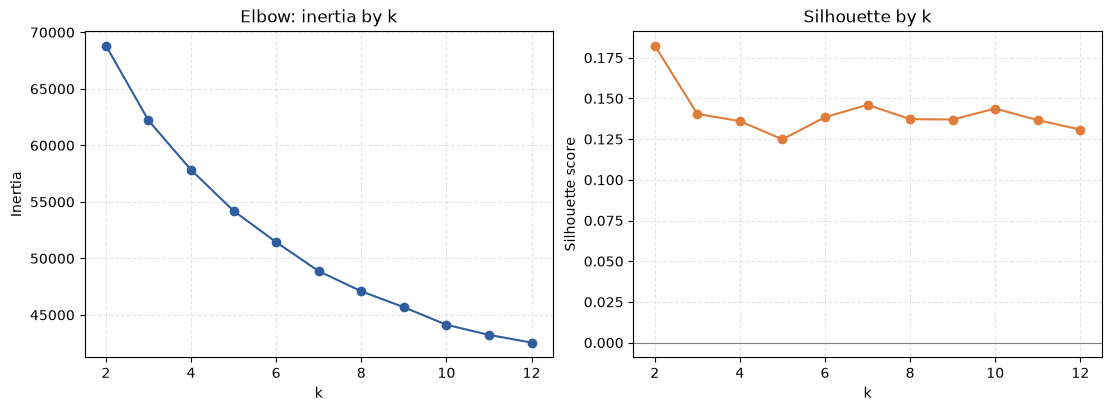

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")

axes[0].plot(diag["k"], diag["inertia"], marker="o", color="#2F5D9E")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow: inertia by k")
axes[0].grid(True, linestyle="--", alpha=0.3)

axes[1].plot(diag["k"], diag["silhouette"], marker="o", color="#E07B39")
axes[1].axhline(0, color="grey", linewidth=0.8)
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette by k")
axes[1].grid(True, linestyle="--", alpha=0.3)

plt.show()

### The chosen k

Set `K` below and state the reason in the same cell, so the decision is visible
next to the code that uses it. Judge it from the two plots: the elbow where
inertia stops falling steeply, and a silhouette that is not still climbing —
if the silhouette peaks at the top of the range, that is evidence the data has
no natural grouping and the number is an artefact of the range searched.


In [7]:
# State the reason in the comment beside K once you have read the two plots.
K = 5

print(f"k = {K}")
print()
print(diag[diag["k"] == K].to_string(index=False))

k = 5

 k      inertia  silhouette
 5 54206.510783    0.124847


## Fit K-Means

In [8]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=K, n_init=10, random_state=42)
labels = km.fit_predict(X_scaled)

cluster_df = mp2.cluster_label_frame(cluster_df, labels, "cluster")

counts = cluster_df["cluster"].value_counts().sort_index()
print("cluster sizes:")
print(counts.to_string())
print()
print(f"smallest cluster: {counts.min()} SA2s")
print(f"largest cluster : {counts.max()} SA2s")
print(f"inertia         : {km.inertia_:,.0f}")

cluster sizes:
cluster
0    684
1    400
2    406
3    552
4    353

smallest cluster: 353 SA2s
largest cluster : 684 SA2s
inertia         : 54,207


## What each cluster looks like

Mean of every feature by cluster. Read the columns, not the rows — for each
feature, which clusters sit above and below the national average.

This is the table the cluster names come from.


In [9]:
# Compare each cluster mean against the national mean, so the reading is
# "above or below average" rather than a raw share.
profile = cluster_df.groupby("cluster")[CLUSTER_FEATURES].mean()
national = cluster_df[CLUSTER_FEATURES].mean()

# Show the features with the widest spread across clusters - those are what
# actually separates the groups. The rest are near-identical everywhere.
spread = (profile.max() - profile.min()).sort_values(ascending=False)
TOP_N = 15
show = spread.head(TOP_N).index.tolist()

print(f"the {TOP_N} features that separate the clusters most:")
print()
display_cols = profile[show].T.round(4)
display_cols["national"] = national[show].round(4)
print(display_cols.to_string())

print()
print(f"n SA2s per cluster:")
print(counts.to_string())

the 15 features that separate the clusters most:

cluster                                                                               0       1       2       3       4  national
tenure_of_household_dwelling_not_owned_and_not_held_in_a_family_trust_share      0.3017  0.2406  0.3213  0.2794  0.6184    0.3364
tenure_of_household_dwelling_owned_or_partly_owned_share                         0.5971  0.5912  0.5935  0.5635  0.3342    0.5490
sector_of_landlord_private_person_trust_or_business_share                        0.9077  0.9576  0.8547  0.9545  0.7140    0.8893
sector_of_landlord_k_inga_ora_housing_nz_share                                   0.0593  0.0049  0.0688  0.0310  0.2276    0.0701
total_household_income_200_001_or_more_share                                     0.1113  0.1335  0.0473  0.2643  0.1097    0.1392
weekly_rent_paid_by_household_200_299_share                                      0.0765  0.2421  0.1893  0.0412  0.0868    0.1167
weekly_rent_paid_by_household_under_200_

### Cluster names

Give each cluster a human name and the two or three numbers that justify it. A
name without a number is a story; the marker wants the reasoning.

Read the table above for which features separate each group, then fill in
`CLUSTER_NAMES` below. Example of the shape —
*"outer-suburban mortgaged families, 68% owner-occupied against a national 51%"*.


In [10]:
# Keyed by the label K-Means assigned. 
CLUSTER_NAMES = {
    0: "Mainstream mixed-tenure suburbs",
    1: "Low-rent owner-occupied",
    2: "Lower-income, one-car households",
    3: "High-income, high-rent",
    4: "State and social housing",
}

names = {k: CLUSTER_NAMES.get(k, f"Cluster {k}")
         for k in sorted(cluster_df["cluster"].unique())}
print(names)


{np.int32(0): 'Mainstream mixed-tenure suburbs', np.int32(1): 'Low-rent owner-occupied', np.int32(2): 'Lower-income, one-car households', np.int32(3): 'High-income, high-rent', np.int32(4): 'State and social housing'}


| Cluster | n | Name | Defining evidence (vs national) |
|---|---|---|---|
| 0 | 684 | Mainstream mixed-tenure suburbs | Owned 0.597 (0.549); private landlord 0.908 (0.889); rent $500–599 0.226 (0.163) |
| 1 | 400 | Low-rent owner-occupied | Rent under $200 0.209 (0.154), $200–299 0.242 (0.117); Kāinga Ora 0.005 (0.070) |
| 2 | 406 | Lower-income, one-car households | One vehicle 0.414 (0.328), two 0.348 (0.394); Kāinga Ora 0.069 (0.070) |
| 3 | 552 | High-income, high-rent | Income $200k+ 0.264 (0.139); rent $600+ 0.215 (0.115), $800+ 0.171 (0.057) |
| 4 | 353 | State and social housing | Kāinga Ora 0.228 (0.070); not-owned 0.618 (0.336); owned 0.334 (0.549) |


## Clusters in geographic space

A cluster solution that only exists in a table is half-argued. This maps the
labels onto the SA2 boundaries — reusing the same shapefile and key
normalisation as notebook 02's crowding map.


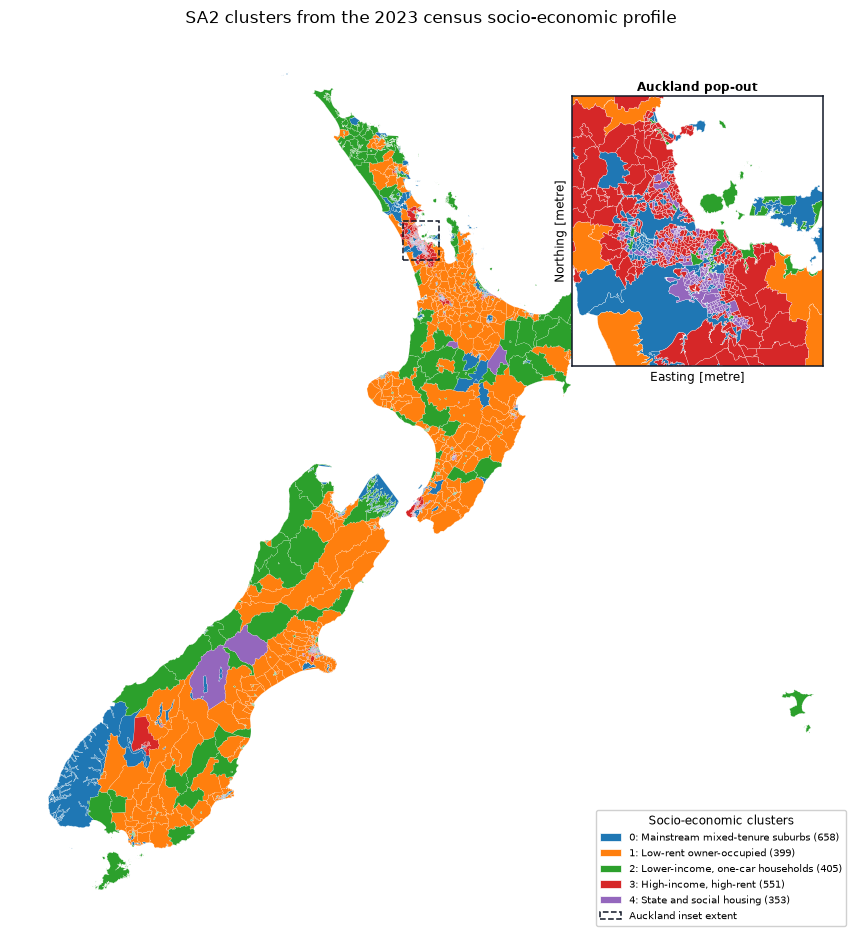

In [11]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# 1. Load SA2 polygons (NZTM EPSG:2193) and exclude only "Oceanic " polygons on the map
sa2_shp = gpd.read_file(DATA / "statistical-area-2-2023-generalised.shp")

gdf = sa2_shp[["SA22023_V1", "geometry"]].copy()
gdf["sa2_key"] = gdf["SA22023_V1"].astype(str).str.extract(r"(\d{4,8})", expand=False)
gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty]
if gdf.crs is not None and gdf.crs.to_epsg() != 2193:
    gdf = gdf.to_crs(epsg=2193)

plot_df = cluster_df.copy()
plot_df["sa2_key"] = plot_df["sa2_code"].astype(str).str.extract(r"(\d{4,8})", expand=False)
if "sa2_name" in plot_df.columns:
    plot_df = plot_df[~plot_df["sa2_name"].astype(str).str.startswith("Oceanic ")].copy()

gdf = gdf.merge(
    plot_df[["sa2_key", "cluster"]].drop_duplicates(subset=["sa2_key"]),
    on="sa2_key",
    how="inner",
    validate="one_to_one",
)

# 2. Main national map (includes Chatham Islands, excludes Oceanic SA2s)
fig, ax = plt.subplots(figsize=(8.5, 10.5), layout="constrained")
gdf.plot(
    column="cluster",
    categorical=True,
    cmap="tab10",
    legend=False,
    missing_kwds={"color": "lightgrey", "edgecolor": "white", "linewidth": 0.2},
    edgecolor="white",
    linewidth=0.1,
    ax=ax,
)

# Auckland bounding box in NZTM (EPSG:2193)
ak_xmin, ak_ymin, ak_xmax, ak_ymax = 1_730_000, 5_885_000, 1_795_000, 5_955_000
ak_box = mpatches.Rectangle(
    (ak_xmin, ak_ymin),
    ak_xmax - ak_xmin,
    ak_ymax - ak_ymin,
    fill=False,
    edgecolor="#111827",
    linewidth=1.1,
    linestyle="--",
    zorder=4,
)
ax.add_patch(ak_box)

# 3. Auckland pop-out inset in the upper-right / mid-right open space
ax_ins = inset_axes(
    ax,
    width="34%",
    height="30%",
    loc="upper right",
    bbox_to_anchor=(0.0, -0.06, 1.0, 1.0),
    bbox_transform=ax.transAxes,
    borderpad=0.8,
)
gdf.cx[ak_xmin:ak_xmax, ak_ymin:ak_ymax].plot(
    column="cluster",
    categorical=True,
    cmap="tab10",
    legend=False,
    edgecolor="white",
    linewidth=0.18,
    ax=ax_ins,
)
ax_ins.set_xlim(ak_xmin, ak_xmax)
ax_ins.set_ylim(ak_ymin, ak_ymax)
ax_ins.set_xticks([])
ax_ins.set_yticks([])
ax_ins.set_title("Auckland pop-out", fontsize=8.5, fontweight="bold", pad=4)
for spine in ax_ins.spines.values():
    spine.set_edgecolor("#111827")
    spine.set_linewidth(1.1)

# 4. Legend with cluster number + name + count in lower right
cmap = plt.get_cmap("tab10")
handles = []
for k in range(K):
    label_text = names.get(k, f"Cluster {k}") if "names" in globals() else f"Cluster {k}"
    n_areas = int((plot_df["cluster"] == k).sum())
    handles.append(
        mpatches.Patch(
            facecolor=cmap(k % 10),
            edgecolor="white",
            linewidth=0.5,
            label=f"{k}: {label_text} ({n_areas})",
        )
    )
handles.append(
    mpatches.Patch(
        fill=False,
        edgecolor="#111827",
        linestyle="--",
        linewidth=1.1,
        label="Auckland inset extent",
    )
)

ax.legend(
    handles=handles,
    title="Socio-economic clusters",
    loc="lower right",
    fontsize=7.5,
    title_fontsize=8.5,
    frameon=True,
    facecolor="white",
    framealpha=0.92,
)
ax.set_axis_off()
ax.set_title("SA2 clusters from the 2023 census socio-economic profile", fontsize=12.5)
plt.show()

mapped 67 of 67 Territorial Authorities (incl. Chatham Islands)


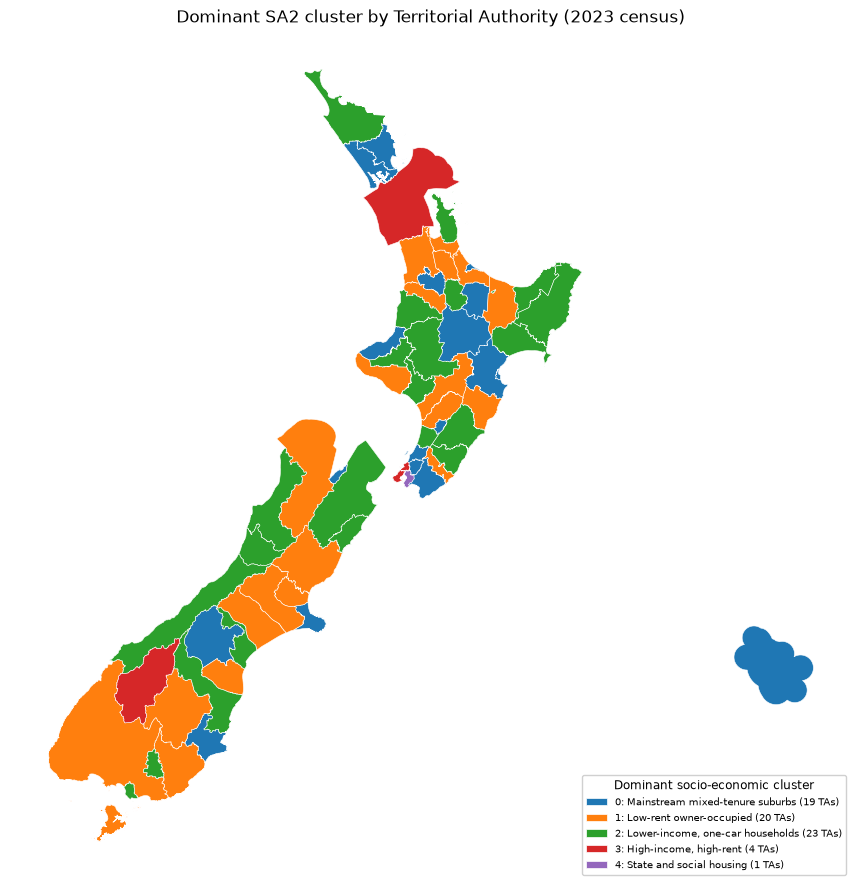

In [12]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# 1. Load the Territorial Authority shapefile from DATA (aligned to NZTM EPSG:2193)
ta_candidates = sorted(DATA.glob("*territorial-authority*.shp"))
assert ta_candidates, f"No Territorial Authority shapefile found in {DATA}"
ta_shp = gpd.read_file(ta_candidates[0])

ta_name_col = next(
    c for c in ("TA2023_V_1", "TA2023_V_2", "ta_name", "TA2023_V1_00_NAME", "TA2023_V1_NAME", "NAME")
    if c in ta_shp.columns
)

ta_gdf = ta_shp[[ta_name_col, "geometry"]].copy()
ta_gdf["ta_key"] = ta_gdf[ta_name_col].astype(str).str.strip()
ta_gdf = ta_gdf[ta_gdf.geometry.notna() & ~ta_gdf.geometry.is_empty]
if ta_gdf.crs is not None and ta_gdf.crs.to_epsg() != 2193:
    ta_gdf = ta_gdf.to_crs(epsg=2193)

# Exclude broad marine/outside-TA entries on the map while keeping Chatham Islands Territory
exclude_mask = (
    ta_gdf["ta_key"].str.startswith("Oceanic ", na=False)
    | ta_gdf["ta_key"].str.contains("outside territorial authority", case=False, na=False)
)
ta_plot_gdf = ta_gdf[~exclude_mask].copy()

# 2. Dominant (modal) cluster per Territorial Authority from SA2 cluster assignments
valid_ta = cluster_df[
    cluster_df["ta_name"].notna()
    & (cluster_df["ta_name"].astype(str).str.strip() != "")
    & cluster_df["cluster"].notna()
    & (~cluster_df["ta_name"].astype(str).str.startswith("Oceanic ", na=False))
].copy()
valid_ta["ta_key"] = valid_ta["ta_name"].astype(str).str.strip()

ta_dominant = (
    valid_ta.groupby("ta_key")["cluster"]
    .agg(lambda s: s.value_counts().index[0])
    .reset_index()
    .rename(columns={"cluster": "dominant_cluster"})
)

ta_plot_gdf = ta_plot_gdf.merge(ta_dominant, on="ta_key", how="left")
print(
    f"mapped {int(ta_plot_gdf['dominant_cluster'].notna().sum()):,} of "
    f"{len(ta_plot_gdf):,} Territorial Authorities (incl. Chatham Islands)"
)

# 3. Plot TA map with cluster names + counts in the lower-right legend
fig, ax = plt.subplots(figsize=(8.5, 10.5), layout="constrained")
ta_plot_gdf.plot(
    column="dominant_cluster",
    categorical=True,
    cmap="tab10",
    legend=False,
    missing_kwds={"color": "lightgrey", "edgecolor": "white", "linewidth": 0.4},
    edgecolor="white",
    linewidth=0.4,
    ax=ax,
)

cmap = plt.get_cmap("tab10")
handles = []
for k in range(K):
    label_text = names.get(k, f"Cluster {k}") if "names" in globals() else f"Cluster {k}"
    n_tas = int((ta_plot_gdf["dominant_cluster"] == k).sum())
    handles.append(
        mpatches.Patch(
            facecolor=cmap(k % 10),
            edgecolor="white",
            linewidth=0.5,
            label=f"{k}: {label_text} ({n_tas} TAs)",
        )
    )

ax.legend(
    handles=handles,
    title="Dominant socio-economic cluster",
    loc="lower right",
    fontsize=7.5,
    title_fontsize=8.5,
    frameon=True,
    facecolor="white",
    framealpha=0.92,
)
ax.set_axis_off()
ax.set_title("Dominant SA2 cluster by Territorial Authority (2023 census)", fontsize=12.5)
plt.show()

### Do the clusters agree with the administrative geographies?
**Partially answered — Territorial Authority (`ta_name`) is now evaluated; Regional Council remains a limitation.**

Now that `ta_name` is attached to each SA2 in the analysis frame, we can measure how closely the **5 K-Means socio-economic clusters** align with **Territorial Authority** boundaries using the **Adjusted Rand Index (`ARI`)**, **Normalised Mutual Information (`NMI`)**, and a TA-by-cluster crosstab:

* **How to read `ARI`:** `ARI` adjusts for agreement by chance (`0` = no better than random assignment, `1` = identical partitions). Even a low-to-moderate positive `ARI` (for example around `0.1`–`0.2`) is a substantive finding rather than a flaw: it shows that socio-economic profiles cut across district lines, with individual Territorial Authorities mixing distinct neighbourhood types rather than forming uniform socio-economic blocks.
* **Remaining limitation (Regional Council):** A direct Regional Council column or concordance table is still not in the frame, so agreement with Regional Councils is not tested here.


In [13]:
import pandas as pd
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# Ensure cluster and ta_name are available on cluster_df
assert "cluster" in cluster_df.columns, "Run the Fit K-Means cell first so cluster_df['cluster'] exists."
assert "ta_name" in cluster_df.columns, "ta_name missing; re-run 02_eda and setup so ta_name is in cluster_df."

eval_df = cluster_df.loc[
    cluster_df["cluster"].notna()
    & cluster_df["ta_name"].notna()
    & (cluster_df["ta_name"].astype(str).str.strip() != ""),
    ["cluster", "ta_name"],
].copy()
eval_df["ta_name"] = eval_df["ta_name"].astype(str).str.strip()

ari = adjusted_rand_score(eval_df["ta_name"], eval_df["cluster"])
nmi = normalized_mutual_info_score(eval_df["ta_name"], eval_df["cluster"])

print("=== K-Means Clusters vs. Territorial Authority (ta_name) ===")
print(f"SA2s evaluated       : {len(eval_df):,} / {len(cluster_df):,}")
print(f"Unique TAs           : {eval_df['ta_name'].nunique()}")
print(f"Unique clusters      : {eval_df['cluster'].nunique()}")
print(f"Adjusted Rand Index  : {ari:.4f}  (0 = chance, 1 = identical)")
print(f"Norm. Mutual Info    : {nmi:.4f}  (0 = independent, 1 = identical)")
print("Regional council     : still not in frame (no regional council concordance/column).")

# Crosstab of SA2 counts by TA and Cluster, sorted by TA size
ct = pd.crosstab(
    eval_df["ta_name"],
    eval_df["cluster"],
    rownames=["Territorial Authority"],
    colnames=["Cluster"],
    margins=True,
    margins_name="Total",
)
body = ct.drop(index="Total").sort_values(by="Total", ascending=False)
ct_sorted = pd.concat([body, ct.loc[["Total"]]])

# Dominant-cluster share (purity) per TA
cluster_cols_present = [c for c in ct.columns if c != "Total"]
ta_purity = (
    body[cluster_cols_present].max(axis=1) / body["Total"]
).sort_values(ascending=False)

print("\n=== Top 15 TAs by Dominant Cluster Share (Most Uniform) ===")
print(ta_purity.head(15).round(3).to_string())

print("\n=== Bottom 15 TAs by Dominant Cluster Share (Most Mixed Across Clusters) ===")
print(ta_purity.tail(15).round(3).to_string())

=== K-Means Clusters vs. Territorial Authority (ta_name) ===
SA2s evaluated       : 2,379 / 2,395
Unique TAs           : 68
Unique clusters      : 5
Adjusted Rand Index  : 0.1007  (0 = chance, 1 = identical)
Norm. Mutual Info    : 0.1755  (0 = independent, 1 = identical)
Regional council     : still not in frame (no regional council concordance/column).

=== Top 15 TAs by Dominant Cluster Share (Most Uniform) ===
Territorial Authority
Buller District                       0.875
Area Outside Territorial Authority    0.846
Kawerau District                      0.750
Whanganui District                    0.714
Ruapehu District                      0.700
Horowhenua District                   0.682
Kapiti Coast District                 0.680
Nelson City                           0.667
Wairoa District                       0.667
Far North District                    0.646
South Waikato District                0.636
Waimate District                      0.625
Carterton District               

## Sensitivity: does adding the composition columns change the answer?

Crowding is defined as household composition against a bedroom requirement, so
the composition and usual-resident columns are the outcome in another form.
They are excluded from the profile clustering — but how much do they matter?

Cluster a second time on the profile **plus** those columns and measure the ARI
between the two solutions. A high value means the composition columns carry
little beyond the profile; a low one means the profile clustering is describing
something different, and this project's central claim is weaker than it looks.


In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler

composition_cols = [
    c for c in df.columns
    if c.startswith((
        "household_composition_",
        "number_of_usual_residents_in_household_",
        "count_of_households_in_occupied",
    ))
]

print(f"{len(composition_cols)} composition columns available")

if not composition_cols:
    print("none found in the frame -- sensitivity run skipped")
else:
    # Same denominators rule as the shares: drop the totals and medians.
    composition_cols = [
        c for c in composition_cols
        if not c.endswith((
            "_total", "_total_stated", "_median",
            "_average", "_not_stated",
            "_unidentifiable",
            "_not_elsewhere_included",
        ))
    ]
    print(f"{len(composition_cols)} after dropping totals and residuals")

    extended = cluster_df[CLUSTER_FEATURES + composition_cols].copy()
    for c in composition_cols:
        extended[c] = extended[c].fillna(extended[c].median())

    X_ext = StandardScaler().fit_transform(extended)
    labels_ext = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(X_ext)

    ari = adjusted_rand_score(labels, labels_ext)
    print()
    print(f"ARI, profile clustering vs profile + composition: {ari:.4f}")
    print()
    if ari > 0.6:
        print("The composition columns add little: the profile clustering is")
        print("capturing most of what they would have told us.")
    else:
        print("The two solutions differ substantially. The composition columns")
        print("carry information the profile does not, which is the circularity")
        print("caveat stated as a number rather than a worry.")

21 composition columns available
13 after dropping totals and residuals

ARI, profile clustering vs profile + composition: 0.3367

The two solutions differ substantially. The composition columns
carry information the profile does not, which is the circularity
caveat stated as a number rather than a worry.


### Sensitivity Takeaway (`ARI = 0.3367`)
Adding the **13** non-total, non-residual household composition and usual-resident columns (`48` features total) to the **35** socio-economic share features produces a moderate Adjusted Rand Index of **`0.3367`** against the main profile-only clusters:

* **Composition carries distinct signal:** An `ARI` of `0.3367` shows that household size and composition shift SA2 group assignments noticeably rather than merely duplicating income, rent, tenure, landlord, vehicle, and telecom shares.
* **Why holding them out matters:** Because crowding is defined relative to household structure and bedroom need, keeping composition and usual-resident counts out of the main profile clustering avoids baking outcome-related structure directly into the groups—quantifying the circularity risk rather than leaving it unexamined.

## Save the labels

Notebook 04 tests whether the cluster label adds predictive power to the
crowding model. The labels are written out here so the two notebooks cannot
drift apart.

`cluster_labels.csv` is keyed on `sa2_code`, so 04 merges it the same way.


In [15]:
out = cluster_df[["sa2_code", "cluster"]].copy()
out.to_csv(mp2.OUT / "cluster_labels.csv", index=False)

print(f"written cluster_labels.csv: {len(out):,} rows")
print()
print(out["cluster"].value_counts().sort_index().to_string())

# Record the k and the clustering features alongside, so 04 and the README can
# quote them without anyone retyping.
cluster_meta = {
    "k": int(K),
    "features": CLUSTER_FEATURES,
    "excluded_from_matrix": DROPPED_FROM_CLUSTERING,
    "n_sa2_clustered": int(len(cluster_df)),
    "imputed_cells": n_imputed,
    "inertia": float(km.inertia_),
    "silhouette_at_k": float(diag.loc[diag["k"] == K, "silhouette"].iloc[0]),
}
(mp2.OUT / "cluster_meta.json").write_text(json.dumps(cluster_meta, indent=2))
print()
print("written cluster_meta.json")

written cluster_labels.csv: 2,395 rows

cluster
0    684
1    400
2    406
3    552
4    353

written cluster_meta.json


In [16]:
import pandas as pd
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# 1. Pick the frame holding cluster labels (cluster_df from cell [8], with fallback to df)
target_df = (
    cluster_df
    if ("cluster_df" in globals() and any(
        c in cluster_df.columns for c in ("cluster", "kmeans_cluster", "cluster_id", "k_cluster", "label")
    ))
    else df.copy()
)

cluster_col = next(
    (c for c in ("cluster", "kmeans_cluster", "cluster_id", "k_cluster", "label") if c in target_df.columns),
    None,
)

# If labels exist in memory from cell [8] but haven't been attached to target_df yet, attach them
if cluster_col is None and "labels" in globals() and len(labels) == len(target_df):
    target_df = target_df.copy()
    target_df["cluster"] = labels
    cluster_col = "cluster"

assert cluster_col is not None, (
    f"Could not find a cluster assignment column. Run cell [8] first. Available columns: {list(target_df.columns)}"
)

# 2. Ensure ta_name is present (already present in 03, with CSV fallback if needed)
if "ta_name" not in target_df.columns:
    frame_path = mp2.OUT / "analysis_frame_features.csv"
    if frame_path.exists():
        feat_df = pd.read_csv(frame_path, usecols=["sa2_code", "ta_name"], dtype={"sa2_code": str})
        target_df = target_df.copy()
        target_df["sa2_code"] = target_df["sa2_code"].astype(str).str.strip()
        target_df = target_df.merge(feat_df.drop_duplicates(subset=["sa2_code"]), on="sa2_code", how="left")

assert "ta_name" in target_df.columns, "ta_name column is missing; re-run the TA join and feature spec cell in 02_eda."

# 3. Filter to rows with both a valid cluster assignment and a non-missing ta_name
eval_df = target_df.loc[
    target_df[cluster_col].notna() & target_df["ta_name"].notna(),
    [cluster_col, "ta_name"],
].copy()
eval_df["ta_name"] = eval_df["ta_name"].astype(str).str.strip()
eval_df = eval_df[eval_df["ta_name"] != ""]

ari = adjusted_rand_score(eval_df["ta_name"], eval_df[cluster_col])
nmi = normalized_mutual_info_score(eval_df["ta_name"], eval_df[cluster_col])

print("=== Cluster vs. Territorial Authority Alignment ===")
print(f"Rows evaluated      : {len(eval_df):,} / {len(target_df):,} SA2s")
print(f"Territorial Auth.   : {eval_df['ta_name'].nunique()} unique TAs")
print(f"Clusters ({cluster_col})  : {eval_df[cluster_col].nunique()} groups")
print(f"Adjusted Rand Index : {ari:.4f}  (0 = random agreement, 1 = identical partitions)")
print(f"Norm. Mutual Info   : {nmi:.4f}  (0 = independent, 1 = identical)")
print()

# 4. Crosstab of SA2 counts by Territorial Authority and Cluster
ct = pd.crosstab(
    eval_df["ta_name"],
    eval_df[cluster_col],
    rownames=["Territorial Authority"],
    colnames=[f"Cluster ({cluster_col})"],
    margins=True,
    margins_name="Total",
)

# Sort TAs by total SA2 count descending (keeping Total at bottom)
body = ct.drop(index="Total").sort_values(by="Total", ascending=False)
ct_sorted = pd.concat([body, ct.loc[["Total"]]])

print("=== SA2 Counts by Territorial Authority and Cluster ===")
print(ct_sorted.to_string())

=== Cluster vs. Territorial Authority Alignment ===
Rows evaluated      : 2,379 / 2,395 SA2s
Territorial Auth.   : 68 unique TAs
Clusters (cluster)  : 5 groups
Adjusted Rand Index : 0.1007  (0 = random agreement, 1 = identical partitions)
Norm. Mutual Info   : 0.1755  (0 = independent, 1 = identical)

=== SA2 Counts by Territorial Authority and Cluster ===
Cluster (cluster)                     0    1    2    3    4  Total
Territorial Authority                                             
Auckland                            114   10   10  330  169    633
Christchurch City                    70   13   26   29   40    178
Wellington City                      10    1    0   50   24     85
Hamilton City                        26    0    1   16   25     68
Dunedin City                         29    9   15    3   12     68
Tauranga City                        32    3    2   18    4     59
Far North District                    7    9   31    0    1     48
Lower Hutt City                      1

In [17]:
# Save SA2 cluster assignments for downstream notebooks (e.g., 04_classification.ipynb)
assert "cluster" in cluster_df.columns, "Run K-Means clustering first so cluster_df['cluster'] exists."

cluster_out = cluster_df[["sa2_code", "ta_name", "cluster"]].copy()
cluster_out_path = mp2.OUT / "sa2_clusters.csv"
cluster_out.to_csv(cluster_out_path, index=False)
print(f"Saved {len(cluster_out):,} rows to {cluster_out_path}")

Saved 2,395 rows to C:\Users\akdux\dsai-mini-project-2\outputs\sa2_clusters.csv


In [18]:
import json

# Persist SA2 -> ta_name lookup and ARI/NMI summary for notebook 05
if "sa2_code" in cluster_df.columns:
    ta_lookup = (
        cluster_df.loc[
            cluster_df["sa2_code"].notna() & cluster_df["ta_name"].notna(),
            ["sa2_code", "ta_name"],
        ]
        .drop_duplicates("sa2_code")
    )
    ta_lookup.to_csv(mp2.OUT / "sa2_ta_lookup.csv", index=False)

ta_eval_summary = {
    "n_evaluated": int(len(eval_df)),
    "n_total": int(len(cluster_df)),
    "n_tas": int(eval_df["ta_name"].nunique()),
    "n_clusters": int(eval_df["cluster"].nunique()),
    "ari_vs_ta": float(ari),
    "nmi_vs_ta": float(nmi),
    "regional_council_present": False,
}
(mp2.OUT / "ta_cluster_alignment.json").write_text(
    json.dumps(ta_eval_summary, indent=2), encoding="utf-8"
)
print(
    f"Persisted sa2_ta_lookup.csv: {len(ta_lookup):,} SA2s across "
    f"{ta_lookup['ta_name'].nunique()} TAs"
)

Persisted sa2_ta_lookup.csv: 2,379 SA2s across 68 TAs
